# **Customer Segmentation using K-Means Clustering**

Customer segmentation means dividing customers into groups based on their behavior or characteristics.
| Customer | Spending | Purchases | Visits |
| -------- | -------: | --------: | -----: |
| A        |  ₹50,000 |        20 |     30 |
| B        |   ₹5,000 |         2 |      4 |
| C        |  ₹45,000 |        18 |     25 |
| D        |   ₹8,000 |         3 |      5 |
| E        |  ₹25,000 |        10 |     15 |

We can create groups such as:

🟢 High-value customers → spend a lot and purchase frequently

🟡 Medium-value customers → average spending and purchases

🔵 Low-value customers → low spending and fewer purchases

**WORKFLOW**

1. Get dataset
       ↓
2. Load dataset
       ↓
3. Understand dataset
       ↓
4. Clean data
       ↓
5. EDA
       ↓
6. Select useful features
       ↓
7. Scale features
       ↓
8. Find optimal number of clusters
       ↓
9. Train K-Means model
       ↓
10. Analyze customer groups
       ↓
11. Visualize clusters
       ↓
12. Save model
       ↓
13. Create prediction program
       ↓
14. Create Gradio UI
       ↓
15. Organize final project
       ↓
16. Create README

In [1]:
import pandas as pd

In [2]:
import numpy as np

In [3]:
import seaborn as sns

In [4]:
import matplotlib.pyplot as plt

In [5]:
data = pd.read_csv('data/Mall_Customers.csv')

In [6]:
data.columns

Index(['CustomerID', 'Genre', 'Age', 'Annual Income (k$)',
       'Spending Score (1-100)'],
      dtype='str')

In [7]:
data.shape

(200, 5)

1. Annual Income → how much the customer earns
2. Spending Score → how much they spend
3. Age → customer's age

For our first clustering model, we'll mainly focus on:

1. Annual Income
2. Spending Score

Why? -> Because these two features make customer groups easy to understand and visualize.

In [8]:
data.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


**Understand Dataset**

In [9]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Genre                   200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB


In [10]:
data.isnull().sum()

CustomerID                0
Genre                     0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

In [11]:
data.duplicated().sum()

np.int64(0)

**EDA**

In [12]:
data.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [13]:
data['Genre'].value_counts()

Genre
Female    112
Male       88
Name: count, dtype: int64

Our main goal is to group similar customers.

For example, imagine: Customer A → Income = 20k, Spending = 10 / Customer B → Income = 25k, Spending = 15

These two customers are relatively similar.

But: Customer C → Income = 120k, Spending = 90

is very different from A and B.

K-Means will try to find these kinds of groups automatically.

**Visualize the Data 📊**

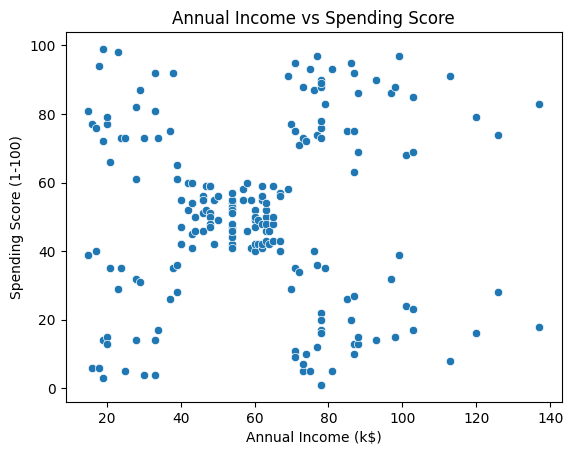

In [14]:
sns.scatterplot(
    x='Annual Income (k$)',
    y='Spending Score (1-100)',
    data = data
)
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title("Annual Income vs Spending Score")
plt.show()

1. Low income + low spending
2. Low income + high spending
3. Medium income + medium spending
4. High income + low spending
5. High income + high spending

**Select Features**

Which columns should we give to K-Means?
1. How much they earn + how much they spend.others columns are useless for segmentation

In [15]:
x = data[['Annual Income (k$)', 'Spending Score (1-100)']]

print(x.head())
print(x.shape)

   Annual Income (k$)  Spending Score (1-100)
0                  15                      39
1                  15                      81
2                  16                       6
3                  16                      77
4                  17                      40
(200, 2)


**Scale Features**

In [16]:
from sklearn.preprocessing import StandardScaler

In [17]:
scaler = StandardScaler()

In [18]:
x_scaled = scaler.fit_transform(x)

StandardScaler converts them to a similar scale.

After scaling, values are centered around 0.You don't need to worry about the negative numbers. They simply represent values below the average.

Why do we scale before K-Means?

K-Means calculates distance between customers.

If one feature has a larger numerical range, it can have more influence on the distance. Scaling prevents that problem and allows both features to contribute more fairly.

In [19]:
print(x_scaled[:5])
print(x_scaled.shape)

[[-1.73899919 -0.43480148]
 [-1.73899919  1.19570407]
 [-1.70082976 -1.71591298]
 [-1.70082976  1.04041783]
 [-1.66266033 -0.39597992]]
(200, 2)


**Find Optimal Number of Clusters**

How many customer groups should K-Means create?

For this, we'll use the Elbow Method.

The idea is simple: we'll try different values of K such as 1, 2, 3, 4, 5, ... 10 and see where adding more clusters stops giving a big improvement.

In [20]:
from sklearn.cluster import KMeans

inertia = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(x_scaled)
    inertia.append(kmeans.inertia_)

print(inertia)

[400.0, 269.6910121927639, 157.70400815035947, 108.92131661364355, 65.56840815571681, 55.057348270385994, 44.86475569922557, 37.228187677585886, 32.39226763033116, 29.981897788243693]


K = 1  → 400.00
K = 2  → 269.69
K = 3  → 157.70
K = 4  → 108.92
K = 5  → 65.57
K = 6  → 55.06
K = 7  → 44.86
K = 8  → 37.23
K = 9  → 32.39
K = 10 → 29.98

What is inertia?

In simple English, inertia tells us how closely customers are grouped around their cluster center.

1. Smaller inertia → customers are closer together.
2. Larger inertia → customers are more spread out.

As we increase K, inertia will always decrease.

The important thing is where the decrease starts becoming much smaller.

Your values show a large improvement up to around K = 5, and after that the improvement becomes smaller.

So we should visualize the Elbow graph to clearly see the bend.

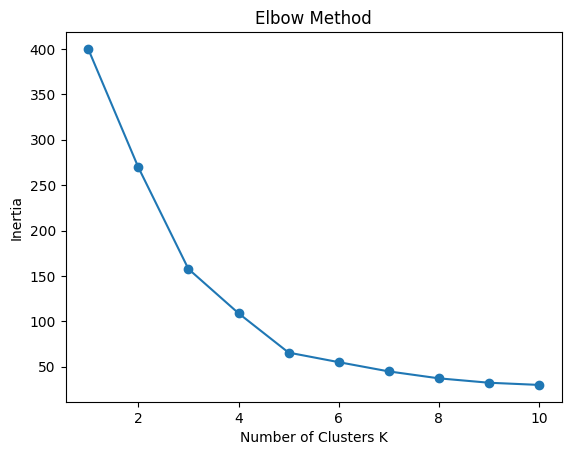

In [21]:
plt.plot(range(1, 11), inertia, marker='o')

plt.xlabel('Number of Clusters K')
plt.ylabel('Inertia')
plt.title('Elbow Method')

plt.show()

**Optimal number of clusters = 5**

**Train K-Means Model**

Now we'll actually create our 5 customer groups.

In [22]:
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)

kmeans.fit(x_scaled)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",5
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",10
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",42
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](5, 2)","[[-0.

Each number represents the group assigned to that customer:

0 → Cluster 0
1 → Cluster 1
2 → Cluster 2
3 → Cluster 3
4 → Cluster 4

So we have 5 customer clusters.

One important thing

The numbers themselves don't have a meaning like:

Cluster 4 = better customer

or

Cluster 0 = worst customer

K-Means simply gives cluster numbers. We will determine what each group represents by looking at their income and spending score.

In [23]:
labels = kmeans.labels_

print(labels)

[4 2 4 2 4 2 4 2 4 2 4 2 4 2 4 2 4 2 4 2 4 2 4 2 4 2 4 2 4 2 4 2 4 2 4 2 4
 2 4 2 4 2 4 0 4 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 1 3 1 0 1 3 1 3 1 0 1 3 1 3 1 3 1 3 1 0 1 3 1 3 1
 3 1 3 1 3 1 3 1 3 1 3 1 3 1 3 1 3 1 3 1 3 1 3 1 3 1 3 1 3 1 3 1 3 1 3 1 3
 1 3 1 3 1 3 1 3 1 3 1 3 1 3 1]


**Analyze Customer Groups**

Now let's add the cluster labels to our original data.

In [24]:
data['Cluster'] = labels

In [25]:
data.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,4
1,2,Male,21,15,81,2
2,3,Female,20,16,6,4
3,4,Female,23,16,77,2
4,5,Female,31,17,40,4


In [ ]:
# calculate the average income and spending score for each cluster
cluster_summary = data.groupby('Cluster')[[
    'Annual Income (k$)',
    'Spending Score (1-100)'
]].mean()


| Cluster | Avg. Income | Avg. Spending Score | Simple description               |
| ------- | ----------: | ------------------: | -------------------------------- |
| **0**   |      55.30k |               49.52 | Average income, average spending |
| **1**   |      86.54k |               82.13 | High income, high spending       |
| **2**   |      25.73k |               79.36 | Low income, high spending        |
| **3**   |      88.20k |               17.11 | High income, low spending        |
| **4**   |      26.30k |               20.91 | Low income, low spending         |


In [ ]:
# it will tell us what each customer group looks like
print(cluster_summary)

         Annual Income (k$)  Spending Score (1-100)
Cluster                                            
0                 55.296296               49.518519
1                 86.538462               82.128205
2                 25.727273               79.363636
3                 88.200000               17.114286
4                 26.304348               20.913043


**Visualize the Clusters**

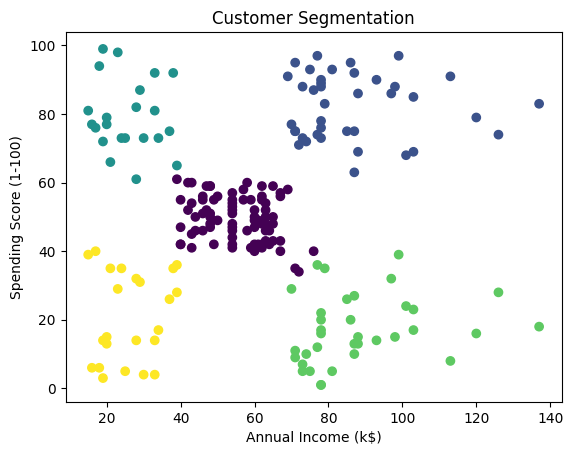

In [28]:
plt.scatter(
    x['Annual Income (k$)'],
    x['Spending Score (1-100)'],
    c=labels
)

plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.title('Customer Segmentation')

plt.show()

**Save the Model**

Now we need to save two things:

1. The trained K-Means model
2. The scaler

In [29]:
import joblib

In [30]:
joblib.dump(kmeans, 'model/customer_kmeans.pkl')

['model/customer_kmeans.pkl']

In [31]:
joblib.dump(scaler, 'model/customer_scaler.pkl')

['model/customer_scaler.pkl']